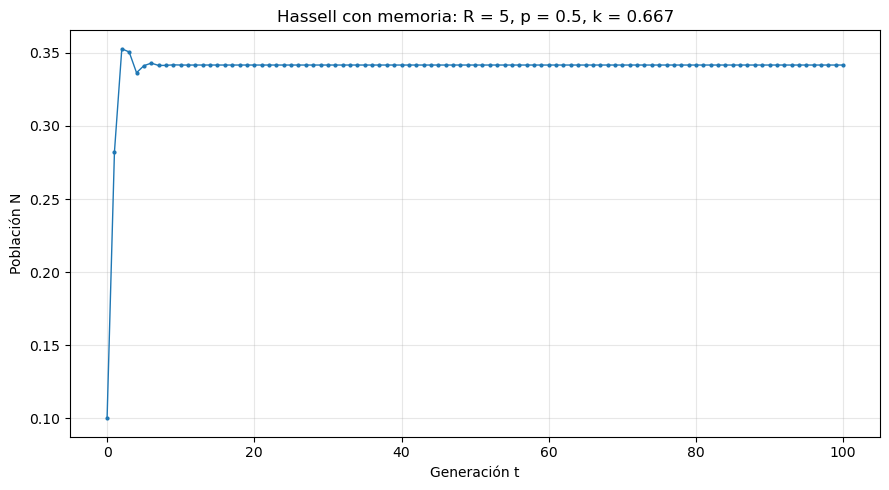

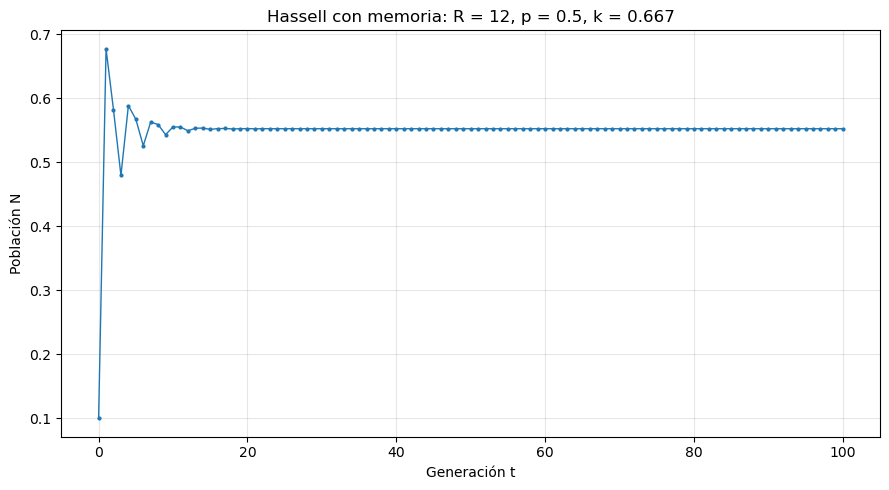

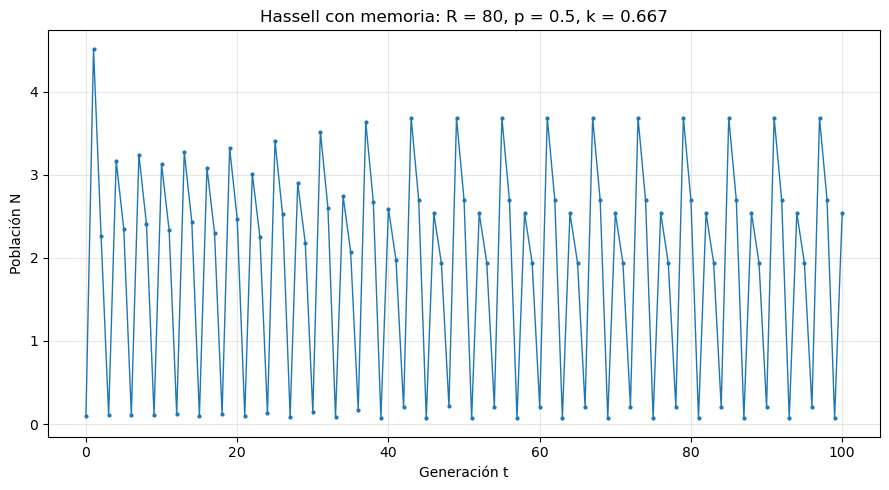

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hassell(N, R, a, b):
    return R * N / (1 + a * N)**b

a = 1.0
b = 6.0
N0 = 0.1
generaciones = 100

p = 0.5
k = 0.666

for R in [5, 12, 80]:
    poblacion = np.zeros(generaciones + 1)

    
    poblacion[0] = N0
    poblacion[1] = hassell(N0, R, a, b)

    for t in range(generaciones - 1):
        poblacion[t + 2] = (
            k * hassell(poblacion[t + 1], R, a, b)
            + p * hassell(poblacion[t], R, a, b)
        )

  
    plt.figure(figsize=(9, 5))
    plt.plot(poblacion, linewidth=1, marker=".", markersize=4)
    plt.xlabel("Generación t")
    plt.ylabel("Población N")
    plt.title(f"Hassell con memoria: R = {R}, p = {p}, k = {k:.3f}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

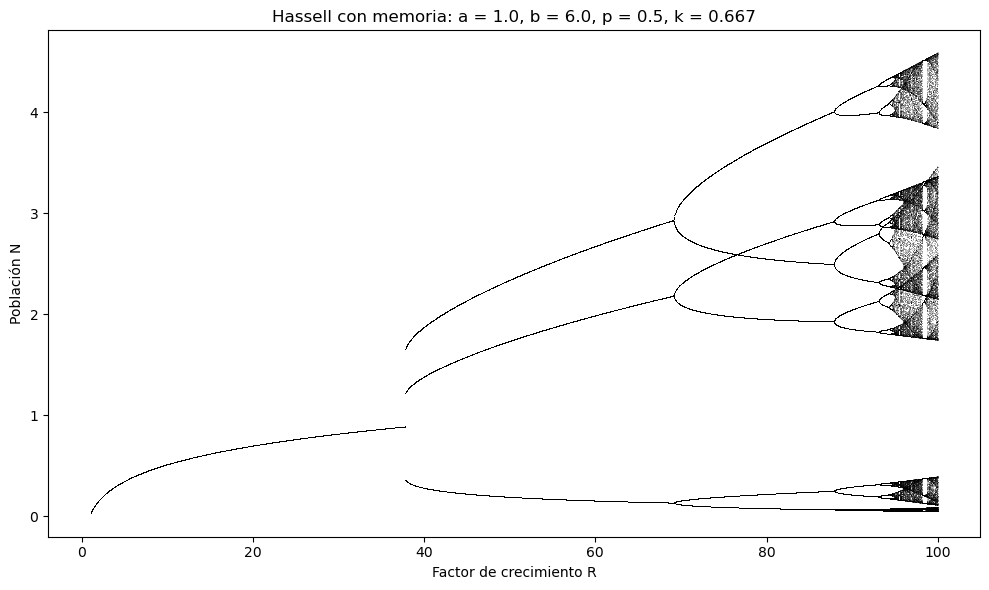

In [ ]:
R_valores = np.linspace(1, 100, 3000)


ayer = np.full_like(R_valores, N0)
hoy = hassell(ayer, R_valores, a, b)

for _ in range(3000):
    manana = (
        k * hassell(hoy, R_valores, a, b)
        + p * hassell(ayer, R_valores, a, b)
    )
    ayer, hoy = hoy, manana


plt.figure(figsize=(10, 6))

for _ in range(300):
    manana = (
        k * hassell(hoy, R_valores, a, b)
        + p * hassell(ayer, R_valores, a, b)
    )
    ayer, hoy = hoy, manana

    plt.plot(R_valores, hoy, ",", color="black", alpha=0.25)

plt.xlabel("Factor de crecimiento R")
plt.ylabel("Población N")
plt.title(
    f"Hassell con memoria: a = {a}, b = {b}, "
    f"p = {p}, k = {k:.3f}"
)
plt.tight_layout()
plt.show()